In [1]:
import numpy as np 
import pandas as pd    
import matplotlib.pyplot as plt   
import seaborn as sns  

In [2]:
df = pd.read_excel(r"C:\Users\vimal_z0\Downloads\ML Files\beer-servings.xlsx")
df

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,1,Albania,89.0,132.0,54.0,4.9,Europe
2,2,Algeria,25.0,0.0,14.0,0.7,Africa
3,3,Andorra,245.0,138.0,312.0,12.4,Europe
4,4,Angola,217.0,57.0,45.0,5.9,Africa
...,...,...,...,...,...,...,...
188,188,Venezuela,NaN,100.0,3.0,7.7,South America
189,189,Vietnam,111.0,2.0,1.0,2.0,Asia
190,190,Yemen,6.0,0.0,0.0,0.1,Asia
191,191,Zambia,32.0,19.0,4.0,2.5,Africa


In [3]:
df.isnull().sum()  # .isnull()- is used to find the null values and .sum() -> is used to give the sum of the values

Unnamed: 0                      0
country                         0
beer_servings                   8
spirit_servings                 8
wine_servings                   6
total_litres_of_pure_alcohol    1
continent                       0
dtype: int64

In [4]:
for i in ["beer_servings", "spirit_servings", "wine_servings", "total_litres_of_pure_alcohol"]:  # .median() -> is used to fill the none values by taking the median of the existing datas 
    df[i] = df[i].fillna(df[i].median())  # .fillna -> method in the Python Pandas library is used to replace missing values (NaN or None) in a DataFrame
df[i]

0       0.0
1       4.9
2       0.7
3      12.4
4       5.9
       ... 
188     7.7
189     2.0
190     0.1
191     2.5
192     4.7
Name: total_litres_of_pure_alcohol, Length: 193, dtype: float64

In [5]:
df.isnull().sum()

Unnamed: 0                      0
country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

Finding Outliers
BoxPlot is used for outlier detection

Text(0.5, 1.0, 'BoxPlot of beer_servings')

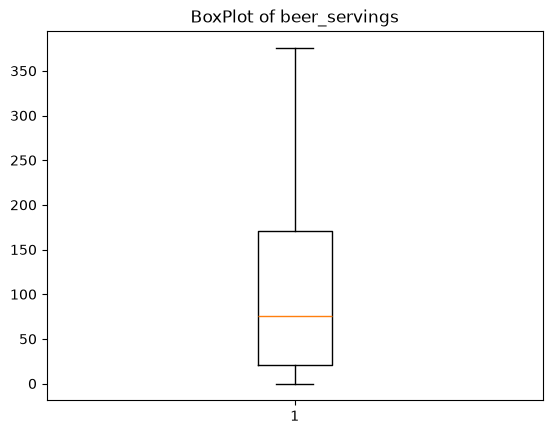

In [6]:
plt.boxplot(df["beer_servings"]) 
plt.title("BoxPlot of beer_servings")

Text(0.5, 1.0, 'BoxPlot of spirit_servings')

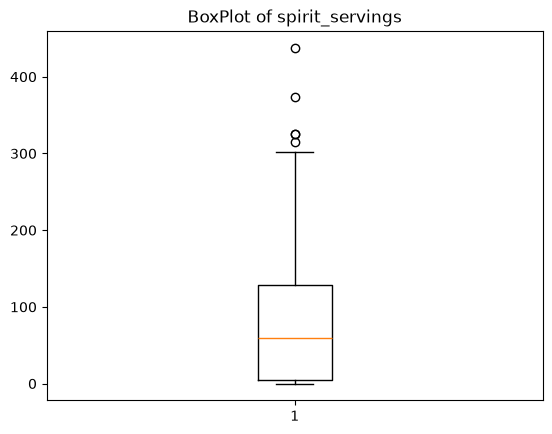

In [7]:
plt.boxplot(df["spirit_servings"])
plt.title("BoxPlot of spirit_servings")

Text(0.5, 1.0, 'BoxPlot of wine_servings')

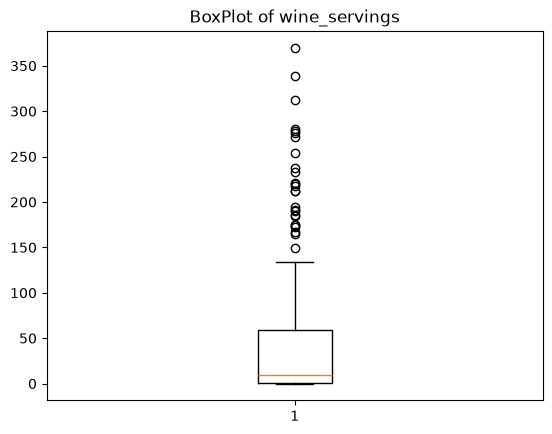

In [8]:
plt.boxplot(df["wine_servings"])
plt.title("BoxPlot of wine_servings")

Text(0.5, 1.0, 'BoxPlot of total_litres_of_pure_alcohol')

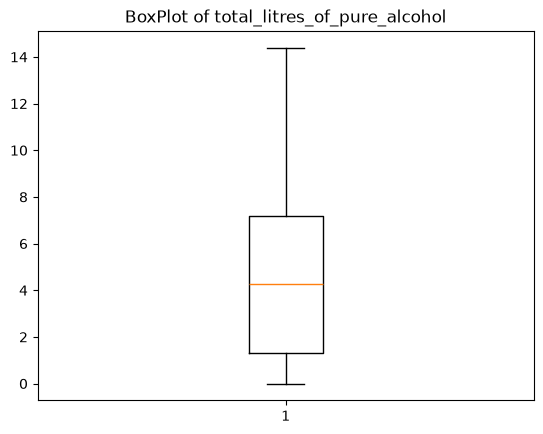

In [9]:
plt.boxplot(df["total_litres_of_pure_alcohol"])
plt.title("BoxPlot of total_litres_of_pure_alcohol")

Text(0.5, 1.0, 'Boxplot of total_litres_of_pure_alcohol')

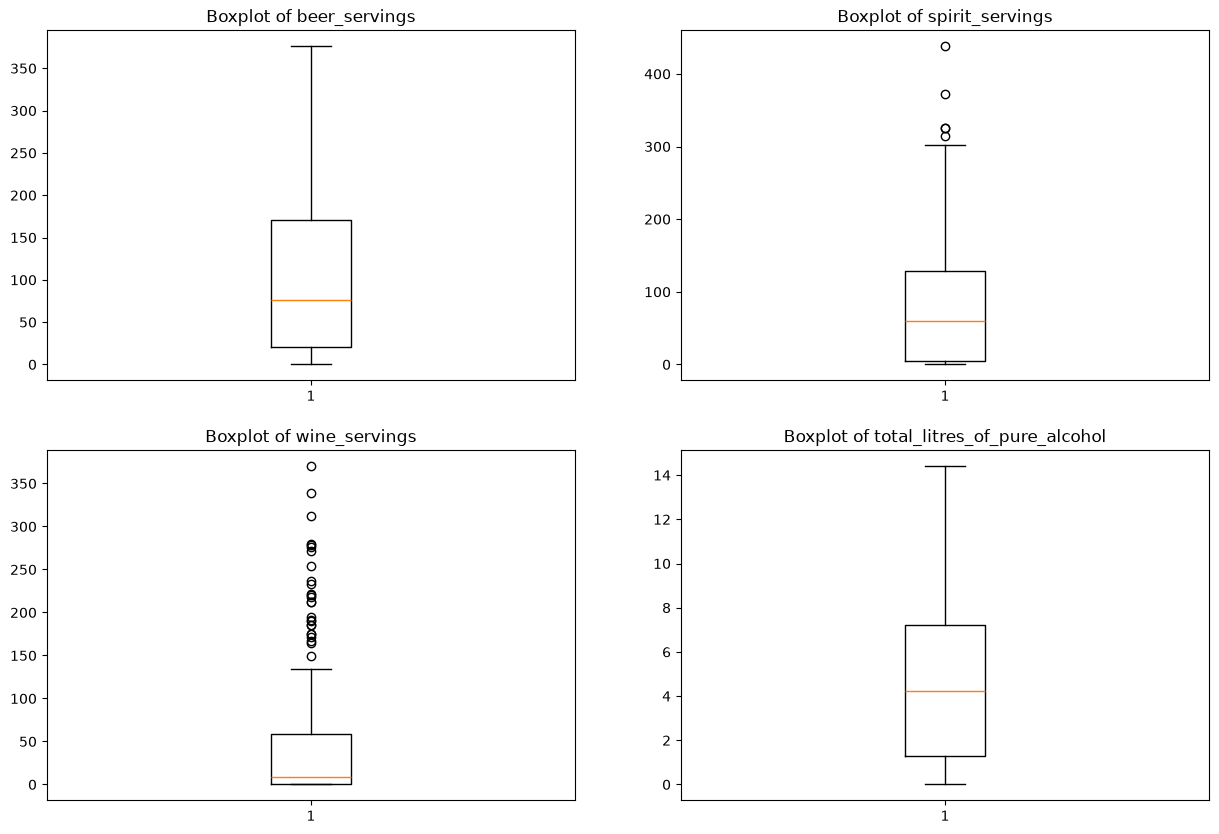

In [10]:
plt.subplots(2,2,figsize=(15,10))
plt.subplot(2,2,1)
plt.boxplot(df["beer_servings"])
plt.title("Boxplot of beer_servings")
plt.subplot(2,2,2)
plt.boxplot(df["spirit_servings"])
plt.title("Boxplot of spirit_servings")
plt.subplot(2,2,3)
plt.boxplot(df["wine_servings"])
plt.title("Boxplot of wine_servings")
plt.subplot(2,2,4)
plt.boxplot(df["total_litres_of_pure_alcohol"])
plt.title("Boxplot of total_litres_of_pure_alcohol")


In [11]:
df.isnull().sum()

Unnamed: 0                      0
country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

In [12]:
Q1 = np.percentile(df["spirit_servings"], 25, method = "midpoint")
Q2 = np.percentile(df["spirit_servings"], 50, method = "midpoint")
Q3 = np.percentile(df["spirit_servings"], 75, method = "midpoint")

print("Q1:",Q1)
print("Q2:",Q2)
print("Q3:",Q3)

Q1: 5.0
Q2: 60.0
Q3: 128.0


In [13]:
IQR = Q3-Q1   #Iterative Outlier Removal
print("IQR:",IQR)

IQR: 123.0


In [14]:
upper_limit = Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
print("Upper_limit:",upper_limit)
print("Lower_limit:",lower_limit)

Upper_limit: 312.5
Lower_limit: -179.5


In [15]:
Outliers =[]
for i in df["spirit_servings"]:
    if (i>upper_limit) or (i<lower_limit):
        Outliers.append(i)
print("Outliers:",Outliers)

Outliers: [373.0, 438.0, 326.0, 326.0, 315.0]


In [16]:
df1 =df["spirit_servings"] > upper_limit
df1

0      False
1      False
2      False
3      False
4      False
       ...  
188    False
189    False
190    False
191    False
192    False
Name: spirit_servings, Length: 193, dtype: bool

In [17]:
df.loc[df1]

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
15,15,Belarus,142.0,373.0,42.0,14.4,Europe
68,68,Grenada,199.0,438.0,28.0,11.9,North America
73,73,Haiti,1.0,326.0,1.0,5.9,North America
141,141,Russian Federation,247.0,326.0,73.0,11.5,Asia
144,144,St. Lucia,171.0,315.0,71.0,10.1,North America


In [18]:
df.loc[df1].index

Index([15, 68, 73, 141, 144], dtype='int64')

In [19]:
df.drop([15, 68, 73, 141, 144] , inplace =True)

In [20]:
df.shape

(188, 7)

In [21]:
df.head(20)

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.00,Asia
1,1,Albania,89.0,132.0,54.0,4.90,Europe
2,2,Algeria,25.0,0.0,14.0,0.70,Africa
3,3,Andorra,245.0,138.0,312.0,12.40,Europe
4,4,Angola,217.0,57.0,45.0,5.90,Africa
5,5,Antigua & Barbuda,102.0,128.0,45.0,4.90,North America
6,6,Argentina,76.0,25.0,221.0,8.30,South America
7,7,Armenia,21.0,179.0,11.0,3.80,Europe
8,8,Australia,261.0,72.0,212.0,10.40,Oceania
9,9,Austria,279.0,75.0,191.0,9.70,Europe


In [22]:
df.shape

(188, 7)

In [23]:
df.reset_index(drop=True)  # .reset_index() -> is used to reset the index of the DataFrame, and drop=True means that the old index will be discarded and not added as a column in the DataFrame. inplace=True means that the operation will be performed on the original DataFrame rather than creating a new one.

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,1,Albania,89.0,132.0,54.0,4.9,Europe
2,2,Algeria,25.0,0.0,14.0,0.7,Africa
3,3,Andorra,245.0,138.0,312.0,12.4,Europe
4,4,Angola,217.0,57.0,45.0,5.9,Africa
...,...,...,...,...,...,...,...
183,188,Venezuela,76.0,100.0,3.0,7.7,South America
184,189,Vietnam,111.0,2.0,1.0,2.0,Asia
185,190,Yemen,6.0,0.0,0.0,0.1,Asia
186,191,Zambia,32.0,19.0,4.0,2.5,Africa


In [24]:
df.head(20)

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.00,Asia
1,1,Albania,89.0,132.0,54.0,4.90,Europe
2,2,Algeria,25.0,0.0,14.0,0.70,Africa
3,3,Andorra,245.0,138.0,312.0,12.40,Europe
4,4,Angola,217.0,57.0,45.0,5.90,Africa
5,5,Antigua & Barbuda,102.0,128.0,45.0,4.90,North America
6,6,Argentina,76.0,25.0,221.0,8.30,South America
7,7,Armenia,21.0,179.0,11.0,3.80,Europe
8,8,Australia,261.0,72.0,212.0,10.40,Oceania
9,9,Austria,279.0,75.0,191.0,9.70,Europe


In [25]:
Outliers =[]
for i in df["spirit_servings"]:
    if (i>upper_limit) or (i<lower_limit):
        Outliers.append(i)
print("Outliers:",Outliers)

Outliers: []
